# XGBoost: next-month realized variance

Expanding-window forecasts for XLB, XLE, XLF, XLI and XLY.

- Target: next-month log realized variance of daily excess returns.
- Volatility input: previous-month log realized variance.
- Macro sets: none, VIX only, macro excluding VIX, and all macro variables.
- Initial training window: 60 months. Monthly refitting; retuning every 24 months.
- Tuning: five expanding chronological validation folds. Validation MSE selects the parameters;
  variance of the same out-of-fold errors provides the log-normal correction. The initial
  training-only block is excluded from both calculations.

Output: `models/forecasting/forecasts/xgb_forecasts.csv`.


## 1. Settings

Data paths, ETFs, sample dates, tuning grid and predictor sets.


In [2]:
import sys
from pathlib import Path

_checkout = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models" / "research_config.py").is_file()),
    None,
)
if _checkout is None:
    raise FileNotFoundError("Start the notebook kernel from within this project checkout.")
sys.path.insert(0, str(_checkout / "models"))
from utils.paths import PROJECT_ROOT, MODELS_DIR, DATASET_DIR, FORECAST_DIR, FORECAST_RESULTS_DIR

import itertools
import warnings

import numpy as np
import pandas as pd
from xgboost import XGBRegressor, DMatrix
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")

import sys
from pathlib import Path



DATA = str(PROJECT_ROOT / "dataset")
RETURNS_PATH = DATA + "/price/clean/daily_returns_panel_ver2.csv"
MACRO_PATH = DATA + "/macro_variables/final_clean/final_macro_data.csv"

ETFS = ["XLB", "XLE", "XLF", "XLI", "XLY"]
MIN_TRAIN = 60                 # initial training months
RETUNE_EVERY = 24              # retuning interval in months
DROP_ONE = False               # optional single-variable exclusion runs

MACRO = ["T10Y2Y", "DGS3MO", "BAA10Y", "CPIAUCSL", "T5YIE", "T5YIE_MINUS_T10YIE",
         "VIXCLS", "INDPRO", "UNRATE", "UMCSENT", "DCOILWTICO"]

# Hyperparameter grid
GRID = [dict(max_depth=d, learning_rate=lr, n_estimators=n)
        for d, lr, n in itertools.product([2, 3], [0.01, 0.03], [100, 300])]                    # 8 combinations
FIXED = dict(subsample=0.7, colsample_bytree=0.8, min_child_weight=3, reg_lambda=5,
             n_jobs=1, random_state=4101, verbosity=0)

# Previous-month log RV
LAGS = ["own_lag"]
FIRST_MONTH = "2003-03-31"   # first target month; 214 out-of-sample forecasts

# Predictor sets
no_vix = [m for m in MACRO if m != "VIXCLS"]
INPUT_SETS = {
    "1 Lags only":         LAGS,
    "2 + VIX only":        LAGS + ["VIXCLS"],
    "3 Macro without VIX": LAGS + no_vix,
    "4 All macro":         LAGS + MACRO,
}
if DROP_ONE:
    for m in MACRO:
        INPUT_SETS[f"All minus {m}"] = LAGS + [x for x in MACRO if x != m]


## 2. Monthly data

Monthly realized variance is the sum of squared daily excess returns. Predictors use information
available through the preceding month. Data are restricted to the configured sample.


In [3]:
daily = pd.read_csv(RETURNS_PATH, parse_dates=["date"]).set_index("date")
month = daily.index.to_period("M").to_timestamp("M")

macro = pd.read_csv(MACRO_PATH, parse_dates=["date"]).set_index("date")
macro.index = macro.index + pd.offsets.MonthEnd(0)
macro = macro[MACRO].shift(1)                      # prior-month macro predictors

data = {}
for etf in ETFS:
    rv = (daily["xret_" + etf] ** 2).groupby(month).sum()                     # monthly excess-return RV
    df = pd.DataFrame({"log_rv": np.log(rv)})
    past = df["log_rv"].shift(1)                   # prior-month log RV
    df["own_lag"] = past                           # one-month volatility predictor
    data[etf] = df.join(macro).dropna().loc[FIRST_MONTH:]  # configured target-month sample
print({etf: len(df) for etf, df in data.items()}, "monthly rows per ETF")


{'XLB': 274, 'XLE': 274, 'XLF': 274, 'XLI': 274, 'XLY': 274} monthly rows per ETF


## 3. Estimation

Chronological cross-validation, expanding-window estimation, an OLS lag baseline, and forecast metrics.


In [4]:
def tune(X, y):
    """Select settings and residual variance with chronological 5-split validation."""
    best = None
    splits = list(TimeSeriesSplit(n_splits=5).split(X))
    for params in GRID:
        pred = np.full(len(y), np.nan)
        for train, valid in splits:
            pred[valid] = XGBRegressor(**FIXED, **params).fit(X[train], y[train]).predict(X[valid])
        # The initial training block has no out-of-fold prediction; exclude it.
        tested = ~np.isnan(pred)
        residuals = y[tested] - pred[tested]
        mse = np.mean(residuals ** 2)
        if best is None or mse < best[0]:
            best = (mse, params, np.var(residuals, ddof=1))
    return best[1], best[2]                        # best settings, chronological CV residual variance


def walk_forward(df, inputs):
    """Monthly expanding-window XGBoost forecasts."""
    X, y = df[inputs].to_numpy(float), df["log_rv"].to_numpy(float)
    rows = []
    for t in range(MIN_TRAIN, len(df)):
        if (t - MIN_TRAIN) % RETUNE_EVERY == 0:
            params, sigma2 = tune(X[:t], y[:t])
        model = XGBRegressor(**FIXED, **params).fit(X[:t], y[:t])
        pred = model.predict(X[t:t + 1])[0]
        # SHAP contributions
        push = model.get_booster().predict(DMatrix(X[t:t + 1]), pred_contribs=True)[0][:-1]
        rows.append({"date": df.index[t], "actual": y[t], "pred": pred,
                     "level_pred": np.exp(pred + sigma2 / 2),     # log-normal correction
                     "sigma2": sigma2,
                     **{"push_" + c: v for c, v in zip(inputs, push)}})
    return pd.DataFrame(rows).set_index("date")


def walk_forward_ols(df, inputs):
    """OLS lag baseline with an expanding estimation window."""
    X, y = df[inputs].to_numpy(float), df["log_rv"].to_numpy(float)
    rows = []
    for t in range(MIN_TRAIN, len(df)):
        A = np.column_stack([np.ones(t), X[:t]])                  # intercept
        beta = np.linalg.lstsq(A, y[:t], rcond=None)[0]
        sigma2 = np.sum((y[:t] - A @ beta) ** 2) / (t - A.shape[1])   # residual variance of the training window
        pred = np.r_[1.0, X[t]] @ beta
        rows.append({"date": df.index[t], "actual": y[t], "pred": pred,
                     "level_pred": np.exp(pred + sigma2 / 2), "sigma2": sigma2})
    return pd.DataFrame(rows).set_index("date")


def score(fc, df):
    err = fc["actual"] - fc["pred"]
    benchmark = df["log_rv"].expanding().mean().shift(1).loc[fc.index]   # historical mean
    ratio = np.exp(fc["actual"]) / fc["level_pred"]
    return {"MSE": (err ** 2).mean(),                                    # log RV
            "R2_OOS": 1 - (err ** 2).sum() / ((fc["actual"] - benchmark) ** 2).sum(),
            "QLIKE": (ratio - np.log(ratio) - 1).mean()}                 # RV level


## 4. Forecast generation

Estimate each specification for every ETF. Progress is reported after each ETF.


In [5]:
forecasts, rows = {}, []
for etf in ETFS:
    for name, inputs in INPUT_SETS.items():
        forecasts[(name, etf)] = walk_forward(data[etf], inputs)
        rows.append({"etf": etf, "inputs": name, **score(forecasts[(name, etf)], data[etf])})
    # OLS lag baseline
    forecasts[("OLS lag baseline", etf)] = walk_forward_ols(data[etf], LAGS)
    rows.append({"etf": etf, "inputs": "OLS lag baseline", **score(forecasts[("OLS lag baseline", etf)], data[etf])})
    print(etf, "done")
results = pd.DataFrame(rows)


XLB done
XLE done
XLF done
XLI done
XLY done


## 5. Forecast accuracy

Log MSE, out-of-sample R² and QLIKE by ETF and specification, followed by the change from adding VIX.


In [6]:
for metric, better in [("MSE", "lower"), ("R2_OOS", "higher"), ("QLIKE", "lower")]:
    print(f"\n{metric} ({better} is better)")
    print(results.pivot(index="etf", columns="inputs", values=metric)
          .loc[ETFS, list(INPUT_SETS) + ["OLS lag baseline"]].round(3))

# Incremental VIX contribution
cols = ["MSE", "R2_OOS", "QLIKE"]
with_vix = results[results.inputs == "4 All macro"].set_index("etf")[cols]
without_vix = results[results.inputs == "3 Macro without VIX"].set_index("etf")[cols]
print("\nAdding VIX to the other macro variables (set 4 minus set 3):")
print((with_vix - without_vix).loc[ETFS].round(3))



MSE (lower is better)
inputs  1 Lags only  2 + VIX only  3 Macro without VIX  4 All macro  \
etf                                                                   
XLB           0.530         0.453                0.494        0.435   
XLE           0.593         0.565                0.577        0.541   
XLF           0.741         0.660                0.657        0.608   
XLI           0.554         0.450                0.518        0.446   
XLY           0.534         0.527                0.507        0.461   

inputs  OLS lag baseline  
etf                       
XLB                0.462  
XLE                0.452  
XLF                0.666  
XLI                0.529  
XLY                0.505  

R2_OOS (higher is better)
inputs  1 Lags only  2 + VIX only  3 Macro without VIX  4 All macro  \
etf                                                                   
XLB           0.367         0.459                0.410        0.481   
XLE           0.368         0.399                0

## 6. Forecast export

Write forecasts to `models/forecasting/forecasts/xgb_forecasts.csv`.

Columns: `model`, `etf`, `date`, `target_date`, `actual_logRV`, `actual_RV`, `fc_log`, `sigma2`, `fc_level`.
`date` is the forecast origin; `target_date` is the following month end.


In [7]:
# Forecast schema includes origin and target dates.
# date: origin month; target_date: forecast month.
# Export for evaluation and portfolio analysis.
import os

NAMES = {"OLS lag baseline": "ols_har_no_macro", "1 Lags only": "xgb_no_macro", "2 + VIX only": "xgb_vix_only",
         "3 Macro without VIX": "xgb_no_vix", "4 All macro": "xgb_full_macro"}
tidy = []
for (name, etf), fc in forecasts.items():
    tidy.append(pd.DataFrame({
        "model": NAMES.get(name, "xgb_" + name), "etf": etf,
        "date": fc.index - pd.offsets.MonthEnd(1),
        "target_date": fc.index,
        "actual_logRV": fc["actual"].values, "actual_RV": np.exp(fc["actual"].values),
        "fc_log": fc["pred"].values, "sigma2": fc["sigma2"].values, "fc_level": fc["level_pred"].values}))
tidy = pd.concat(tidy, ignore_index=True)

out_dir = PROJECT_ROOT / "models" / "forecasting" / "forecasts"
os.makedirs(out_dir, exist_ok=True)
out_file = os.path.join(out_dir, "xgb_forecasts.csv")
tidy.to_csv(out_file, index=False)
print("\nSaved", tidy.shape, "->", os.path.abspath(out_file))



Saved (5350, 9) -> /Users/lyc/Documents/GitHub/dse4101capstone-project/models/forecasting/forecasts/xgb_forecasts.csv


## 7. Feature contributions

Mean absolute SHAP contributions for the full-macro specification, in log-variance units and as
percentages of total contributions.


In [8]:
full = "4 All macro"
push = pd.DataFrame({etf: forecasts[(full, etf)].filter(like="push_").abs().mean() for etf in ETFS})
push.index = push.index.str.replace("push_", "")
push["average"] = push.mean(axis=1)
print("\nAverage push of each input on the forecast (set 4):")
print(push.sort_values("average", ascending=False).round(3))
print("\nShare of the total push:")
print((push / push.sum() * 100).sort_values("average", ascending=False).round(1))


# Export full-precision Appendix C3 evidence from this forecast run.
# The average share normalises the mean absolute contribution across ETFs;
# it is not the arithmetic mean of the five sector percentages.
FORECAST_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
push.rename_axis("predictor").to_csv(FORECAST_RESULTS_DIR / "xgb_shap_mean_abs.csv")
(push / push.sum() * 100).rename_axis("predictor").to_csv(
    FORECAST_RESULTS_DIR / "xgb_shap_share_pct.csv")
contributions = []
for etf in ETFS:
    values = forecasts[(full, etf)].filter(like="push_").copy()
    values.columns = values.columns.str.removeprefix("push_")
    contributions.append(values.rename_axis("target_date").reset_index().assign(etf=etf))
pd.concat(contributions, ignore_index=True).to_csv(
    FORECAST_RESULTS_DIR / "xgb_shap_contributions.csv", index=False)



Average push of each input on the forecast (set 4):
                      XLB    XLE    XLF    XLI    XLY  average
VIXCLS              0.300  0.075  0.320  0.360  0.317    0.274
own_lag             0.126  0.263  0.274  0.112  0.181    0.191
UMCSENT             0.061  0.123  0.173  0.085  0.129    0.114
BAA10Y              0.112  0.049  0.133  0.092  0.089    0.095
CPIAUCSL            0.058  0.061  0.074  0.060  0.078    0.066
DCOILWTICO          0.063  0.049  0.075  0.047  0.052    0.057
DGS3MO              0.056  0.052  0.054  0.046  0.074    0.056
T5YIE               0.058  0.044  0.049  0.046  0.034    0.046
T5YIE_MINUS_T10YIE  0.042  0.051  0.042  0.046  0.044    0.045
T10Y2Y              0.024  0.046  0.046  0.034  0.031    0.036
UNRATE              0.030  0.040  0.029  0.050  0.030    0.036
INDPRO              0.024  0.031  0.037  0.021  0.026    0.028

Share of the total push:
                     XLB        XLE   XLF   XLI        XLY    average
VIXCLS              31.4   8.500

## 8. Tree diagnostic

First tree from a model fitted to the full XLF sample for inspection only. The diagram requires
Graphviz; the text representation is always printed. This diagnostic does not affect forecasts.



First tree for XLF:
0:[T5YIE_MINUS_T10YIE<-0.597000003] yes=1,no=2,missing=1
	1:leaf=-0.0426014811
	2:leaf=-0.1938041

Tree diagram unavailable; text representation shown above.


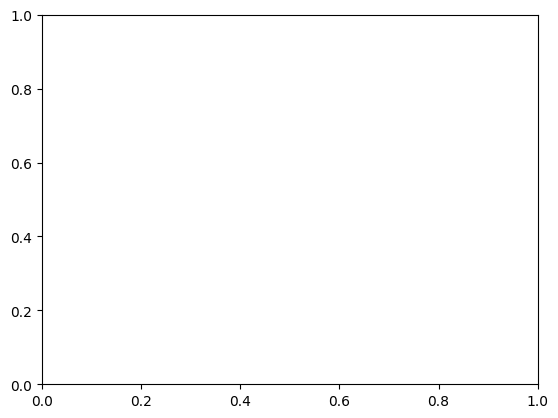

In [9]:
TREE_ETF = "XLF"
inputs = INPUT_SETS[full]
tree = XGBRegressor(**FIXED, max_depth=2, learning_rate=0.03, n_estimators=300)
tree.fit(data[TREE_ETF][inputs], data[TREE_ETF]["log_rv"])
print(f"\nFirst tree for {TREE_ETF}:")
print(tree.get_booster().get_dump()[0])
try:                                               # optional diagram
    import matplotlib.pyplot as plt
    from xgboost import plot_tree
    plot_tree(tree, num_trees=0)
    plt.show()
except Exception as e:
    print("Tree diagram unavailable; text representation shown above.")


## 9. Exploratory Clark–West comparisons

Pairwise comparisons of specifications with additional predictors, using log-MSE differentials,
one-sided p-values and Newey–West variance with three lags. Positive adjusted gain favours the
larger specification. Significance: `***` 1%, `**` 5%, `*` 10%.

The test's fixed-parameter theory does not directly cover tuned XGBoost. Results are exploratory;
p-values are not adjusted for multiple comparisons.


In [10]:
from scipy import stats

NW_LAGS = 3                                         # Newey-West lags for the variance

# Smaller specification, larger specification, comparison label.
NESTED = [("1 Lags only",         "2 + VIX only",        "VIX on top of lags"),
          ("1 Lags only",         "4 All macro",         "All macro on top of lags"),
          ("3 Macro without VIX", "4 All macro",         "VIX on top of the other macro"),
          ("1 Lags only",         "3 Macro without VIX", "Non-VIX macro on top of lags")]


def newey_west_var(d, lags=NW_LAGS):
    """Newey-West variance of the mean of d."""
    d = d - d.mean()
    T = len(d)
    v = np.sum(d * d) / T
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * np.sum(d[k:] * d[:-k]) / T
    return v / T


def clark_west(actual, f_small, f_large):
    """Clark-West adjusted MSPE test. One-sided: H1 = the larger model forecasts better."""
    adj = (actual - f_small) ** 2 - ((actual - f_large) ** 2 - (f_small - f_large) ** 2)
    adj = adj.to_numpy()
    stat = adj.mean() / np.sqrt(newey_west_var(adj))
    return adj.mean(), stat, stats.norm.sf(stat)


cw_rows = []
for small, large, question in NESTED:
    for etf in ETFS:
        a, b = forecasts[(small, etf)], forecasts[(large, etf)]
        gain, stat, p = clark_west(a["actual"], a["pred"], b["pred"])
        stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""
        cw_rows.append({"question": question, "etf": etf, "avg. gain": gain, "CW stat": stat,
                        "p-value": p, "sig.": stars})
cw = pd.DataFrame(cw_rows)

print("Clark-West one-sided p-values:")
print(cw.pivot(index="question", columns="etf", values="p-value")[ETFS].round(3))
print("\nAverage gain in squared error (positive = larger model better):")
print(cw.pivot(index="question", columns="etf", values="avg. gain")[ETFS].round(3))
print("\nFull table:")
cw.round(3)


Clark-West one-sided p-values:
etf                            XLB    XLE  XLF  XLI  XLY
question                                                
All macro on top of lags       0.0  0.000  0.0  0.0  0.0
Non-VIX macro on top of lags   0.0  0.000  0.0  0.0  0.0
VIX on top of lags             0.0  0.002  0.0  0.0  0.0
VIX on top of the other macro  0.0  0.014  0.0  0.0  0.0

Average gain in squared error (positive = larger model better):
etf                              XLB    XLE    XLF    XLI    XLY
question                                                        
All macro on top of lags       0.234  0.133  0.361  0.278  0.193
Non-VIX macro on top of lags   0.144  0.108  0.278  0.175  0.134
VIX on top of lags             0.140  0.102  0.180  0.171  0.084
VIX on top of the other macro  0.120  0.085  0.113  0.142  0.094

Full table:


,question,etf,avg. gain,CW stat,p-value,sig.
0,VIX on top of lags,XLB,0.140,5.156,0.000,***
1,VIX on top of lags,XLE,0.102,2.953,0.002,***
2,VIX on top of lags,XLF,0.180,4.905,0.000,***
3,VIX on top of lags,XLI,0.171,6.241,0.000,***
4,VIX on top of lags,XLY,0.084,3.765,0.000,***
5,All macro on top of lags,XLB,0.234,6.050,0.000,***
6,All macro on top of lags,XLE,0.133,4.424,0.000,***
7,All macro on top of lags,XLF,0.361,7.115,0.000,***
8,All macro on top of lags,XLI,0.278,6.214,0.000,***
9,All macro on top of lags,XLY,0.193,6.463,0.000,***


## Interpretation

The VIX comparisons measure its incremental forecast contribution. The non-VIX comparison
measures the contribution of other macro predictors. Nonsignificance does not establish equivalence.
